# Ders 01 · 2D ısı iletimi — referans çözümü adım adım kurmak

**Kolay PINN · Türkişi Engineering** · Lisans + yüksek lisans · Adım 1–3

Bu defter ders destesinin uygulamalı eşidir. Hücreleri sırayla çalıştırarak problemi tanımlayacak,
boyutsuzlaştıracak, sonlu farklarla (FDM) çözecek ve sonucu analitik çözüme karşı doğrulayacaksınız.
Sonunda elinizde, ileride PINN'i sınayacağımız **referans çözüm** olacak.

**Öğrenme hedefleri**
1. Konvektif sınır için $\bar h$'yi korelasyondan hesaplamak ve Biot sayısını yorumlamak
2. Problemi boyutsuzlaştırıp tek parametreye, $\mathrm{Bi}$'ye indirmek
3. Robin koşullu Laplace denklemini hayalet düğümle ayrıklaştırıp çözmek
4. Sayısal çözümü seri çözüme karşı sınamak ve yakınsama mertebesini okumak *(yüksek lisans derinliği)*

> 🔎 **Kontrol sorusu** kutularında önce kendiniz düşünün, sonra cevabı açın.

In [1]:
# Kurulum: repo kökünü yola ekle, ortak stil ve paleti yükle
import sys, json, time
from pathlib import Path

CASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ROOT = CASE.parents[1]
sys.path.insert(0, str(ROOT))

import logging, warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from IPython.display import Image, display

from kolay_pinn.style import use_slide_style, C, INK, MUTED, cmap_thermal, cmap_error
use_slide_style()
plt.rcParams["figure.dpi"] = 110

ASSETS = CASE / "lecture" / "assets"
def goster(ad, genislik=520):
    "Ders slaytlarındaki görseli göster."
    display(Image(filename=str(ASSETS / ad), width=genislik))

print("numpy", np.__version__, "· CASE =", CASE.name)

numpy 2.5.3 · CASE = 01-2d-heat-conduction


---
## 1 · Problemi tanımla

Üç kenarı $70\,^\circ\mathrm{C}$'de tutulan $L = 0.1$ m'lik kare çelik plaka, alt kenarı boyunca
$1$ m/s hızla akan $20\,^\circ\mathrm{C}$ suyla soğutuluyor. Kararlı sıcaklık dağılımını ve alttan çekilen ısıyı arıyoruz.

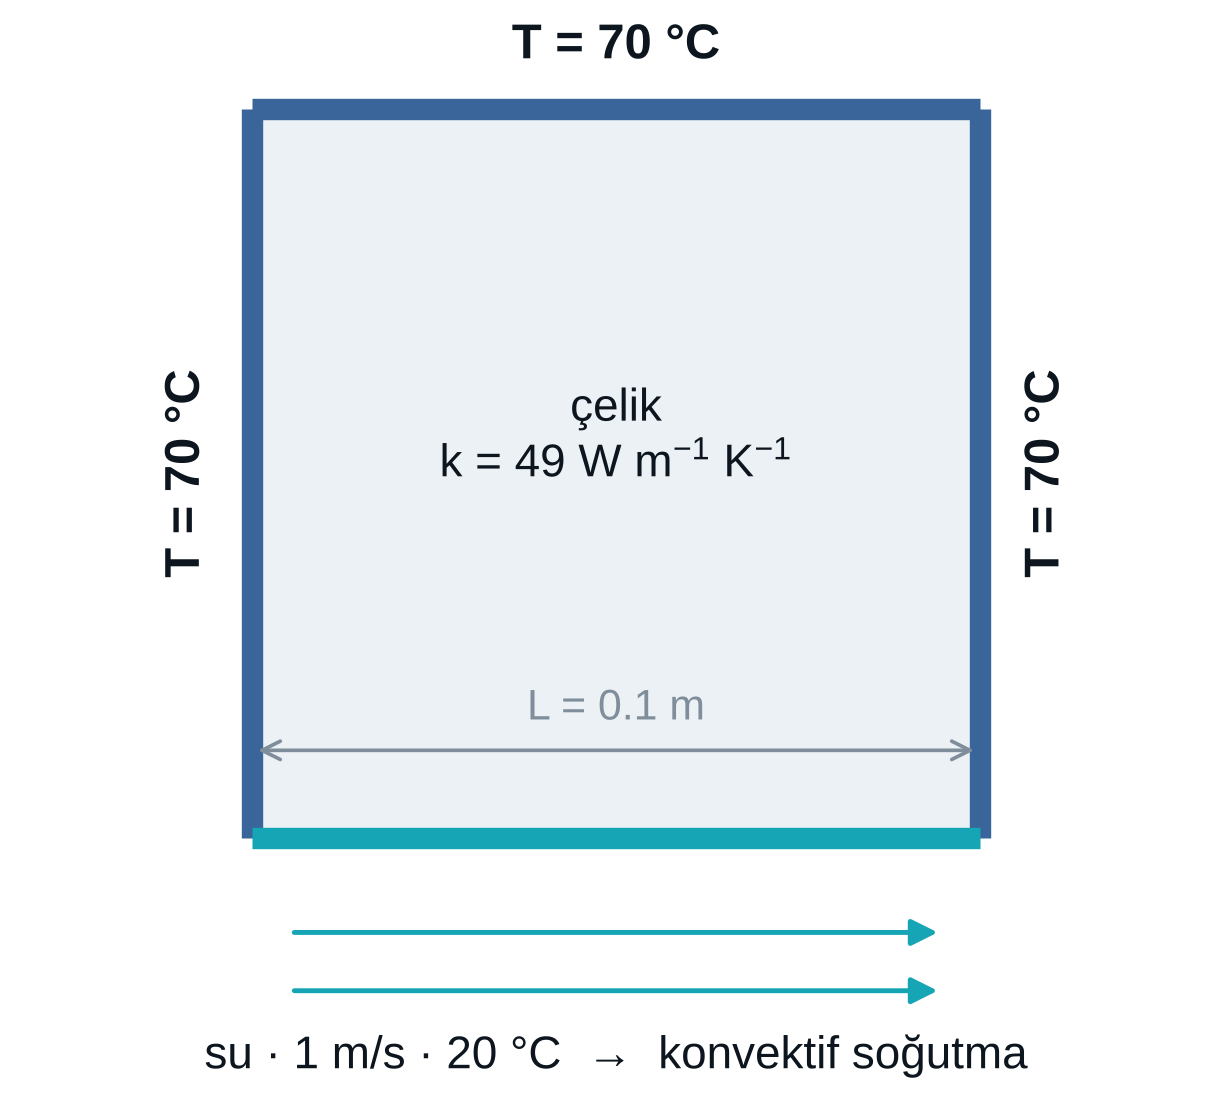

In [2]:
goster("01_schematic.png", 430)

In [3]:
# Verilenler (SI birimleri)
L      = 0.1      # plaka boyu [m]
k      = 49.0     # çelik ısı iletim katsayısı [W/m K]
T_w    = 70.0     # duvar sıcaklığı [°C]
T_inf  = 20.0     # su sıcaklığı [°C]
U      = 1.0      # su hızı [m/s]

# Su özellikleri, 20 °C (Incropera, Tablo A.6)
nu_w, k_f, Pr = 1.004e-6, 0.598, 7.01

### 1.1 Su tarafının ısı taşınım katsayısı

Akış laminer mi? Reynolds sayısı:

$$\mathrm{Re}_L = \frac{U L}{\nu}$$

Laminer ($\mathrm{Re}_L < 5\times10^5$), izotermal düz levha için ortalama Nusselt sayısı ve ondan $\bar h$:

$$\overline{\mathrm{Nu}}_L = 0.664\,\mathrm{Re}_L^{1/2}\,\mathrm{Pr}^{1/3},
\qquad \bar h = \frac{\overline{\mathrm{Nu}}_L\,k_f}{L}$$

In [4]:
Re = U * L / nu_w
print(f"Re_L = {Re:,.0f}  ->  {'laminer' if Re < 5e5 else 'türbülanslı'}")

Nu = 0.664 * Re**0.5 * Pr**(1/3)
h  = Nu * k_f / L
print(f"Nu_L = {Nu:.1f}")
print(f"h    = {h:,.0f} W/m²K")

Re_L = 99,602  ->  laminer
Nu_L = 401.1
h    = 2,398 W/m²K


### 1.2 Biot sayısı

$$\mathrm{Bi} = \frac{\bar h\,L}{k} = \frac{\text{plaka içindeki iletim direnci } (L/k)}{\text{su tarafındaki konveksiyon direnci } (1/\bar h)}$$

In [5]:
Bi = h * L / k
print(f"Bi = {Bi:.3f}")
print(f"Verilen h = 2000 ile: Bi = {2000 * L / k:.3f}")

Bi = 4.895
Verilen h = 2000 ile: Bi = 4.082


$\mathrm{Bi} \approx 4.9 \gg 0.1$: toplu kapasite yaklaşımı geçersiz, plakada güçlü bir gradyan beklenir.
Aşağıda dört farklı Bi için alt yüzey profili var (seri çözümü 3. bölümde kendimiz yazacağız):

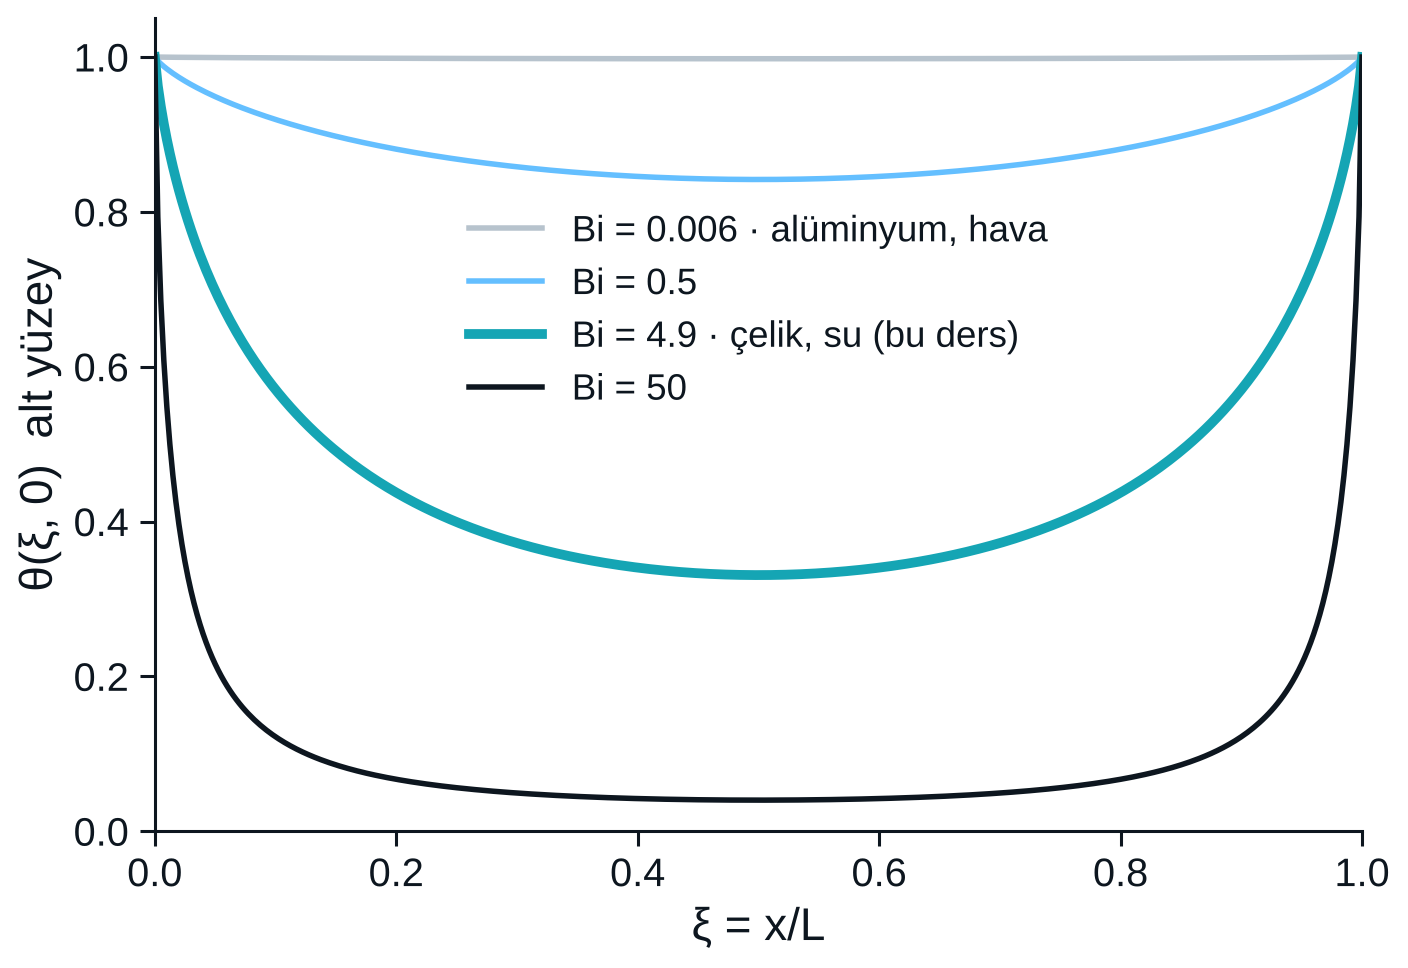

In [6]:
goster("02_bi_regimes.png", 560)

<details><summary>🔎 <b>Kontrol sorusu:</b> Plaka alüminyum (k = 237 W/m K) olsaydı Bi kaç olurdu?</summary>

$\mathrm{Bi} = 2398 \times 0.1 / 237 \approx 1.0$. Gradyan zayıflar; alt yüzeyin ortası bugünkü 36.5 °C'den daha sıcak kalır.
Aşağıdaki hücreyle doğrulayın.
</details>

In [7]:
print(f"alüminyum: Bi = {h * L / 237:.2f}")

alüminyum: Bi = 1.01


---
## 2 · Boyutsuzlaştır

Ölçekler:

$$\theta = \frac{T - T_\infty}{T_w - T_\infty}, \qquad \xi = \frac{x}{L}, \qquad \eta = \frac{y}{L}$$

Bu tanımlarla problem tek parametreye iner:

$$
\begin{aligned}
&\frac{\partial^2\theta}{\partial\xi^2} + \frac{\partial^2\theta}{\partial\eta^2} = 0, && (\xi,\eta)\in[0,1]^2 \\
&\theta = 1, && \xi = 0,\ \xi = 1,\ \eta = 1 \\
&\frac{\partial\theta}{\partial\eta} = \mathrm{Bi}\,\theta, && \eta = 0
\end{aligned}
$$

**Robin koşulunun türetilmesi.** Alt yüzeyde dışa dönük normal $-y$ yönünde; plakadan suya giden iletim akısı
konveksiyonla taşınana eşit. $T - T_\infty = \Delta T\,\theta$ ve $y = L\eta$ yazınca $\Delta T$ sadeleşir:

$$k\,\frac{\partial T}{\partial y} = \bar h\,(T - T_\infty)
\;\Longrightarrow\;
\frac{k\,\Delta T}{L}\,\frac{\partial\theta}{\partial\eta} = \bar h\,\Delta T\,\theta
\;\Longrightarrow\;
\frac{\partial\theta}{\partial\eta} = \mathrm{Bi}\,\theta$$

In [8]:
dT = T_w - T_inf
to_theta   = lambda T: (T - T_inf) / dT
to_celsius = lambda th: T_inf + dT * th

print("70 °C ->", to_theta(70.0), "  ·  20 °C ->", to_theta(20.0), "  ·  θ = 0.33 ->", to_celsius(0.33), "°C")

70 °C -> 1.0   ·  20 °C -> 0.0   ·  θ = 0.33 -> 36.5 °C


<details><summary>🔎 <b>Kontrol sorusu:</b> Boyutlu problemde kaç bağımsız parametre vardı, boyutsuzda kaç tane kaldı?</summary>

Boyutlu: $L, k, \bar h, T_w, T_\infty$ — beş parametre. Boyutsuz: yalnızca $\mathrm{Bi}$.
Parametrik bir çalışmada beş boyutlu uzay yerine tek bir eksen taranır; Adım 8'deki parametrik PINN'in girdisi de budur.
</details>

---
## 3 · FDM ile çöz

### 3.1 Isınma: merkezi fark gerçekten ikinci mertebe mi?

İkinci türevin merkezi fark yaklaşımı:

$$\frac{\partial^2 f}{\partial x^2} \approx \frac{f_{i+1} - 2f_i + f_{i-1}}{\Delta x^2}, \qquad \text{kesme hatası} \;\propto\; \Delta x^2$$

Bunu bilinen bir fonksiyonla sınayalım: $f = \sin(\pi x)$, $f'' = -\pi^2 \sin(\pi x)$.

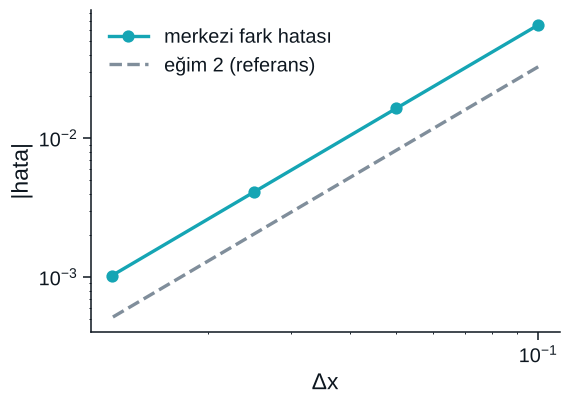

ölçülen mertebe p = 2.00


In [9]:
x0 = 0.3
dxs = np.array([0.1, 0.05, 0.025, 0.0125])
f = lambda x: np.sin(np.pi * x)
hata = [abs((f(x0 + d) - 2 * f(x0) + f(x0 - d)) / d**2 + np.pi**2 * f(x0)) for d in dxs]
p = np.polyfit(np.log(dxs), np.log(hata), 1)[0]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.loglog(dxs, hata, "o-", color=C["plan"], label="merkezi fark hatası")
ax.loglog(dxs, 0.5 * hata[0] * (dxs / dxs[0])**2, "--", color=MUTED, label="eğim 2 (referans)")
ax.set(xlabel="Δx", ylabel="|hata|"); ax.legend()
from matplotlib.ticker import NullFormatter
ax.xaxis.set_minor_formatter(NullFormatter())
plt.show()
print(f"ölçülen mertebe p = {p:.2f}")

### 3.2 Ağ ve düğüm türleri

$N\times N$ düzgün bir düğüm ağı kuruyoruz, $\Delta = 1/(N-1)$. Her düğüm üç türden biri:
- **Dirichlet** (sol, sağ, üst kenar ve alt köşeler): $\theta = 1$, bilinen
- **Robin** (alt kenar, köşeler hariç): yüzey düğümü, bilinmeyen
- **İç düğüm**: bilinmeyen

Küçük bir ağla ($N = 7$) görelim:

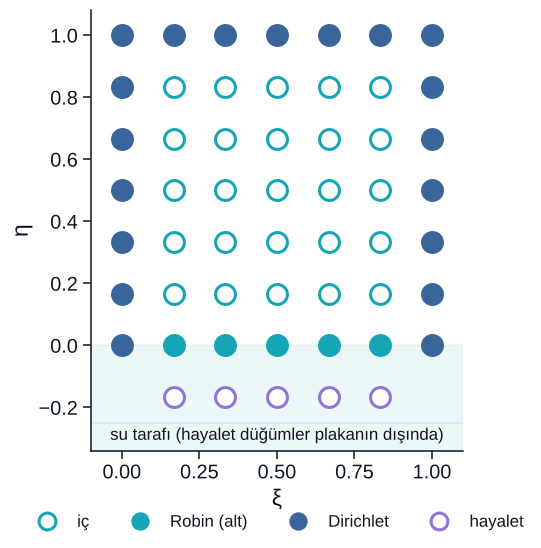

bilinmeyen sayısı: 30 / 49


In [10]:
def dugum_turu(N):
    "0 = iç, 1 = Robin (alt kenar), 2 = Dirichlet"
    tur = np.zeros((N, N), dtype=int)        # tur[j, i]  (j: y, i: x)
    tur[0, :] = 1
    tur[:, 0] = tur[:, -1] = tur[-1, :] = 2
    return tur

N = 7
tur = dugum_turu(N)
xs = np.linspace(0, 1, N)
fig, ax = plt.subplots(figsize=(5.2, 5.2))
for j in range(N):
    for i in range(N):
        c, fc = {0: (C["plan"], C["kagit"]), 1: (C["plan"], C["plan"]), 2: (C["celik_mavisi"], C["celik_mavisi"])}[tur[j, i]]
        ax.plot(xs[i], xs[j], "o", ms=13, mec=c, mfc=fc, mew=2)
for i in range(1, N - 1):      # hayalet düğümler (suyun içinde)
    ax.plot(xs[i], -xs[1], "o", ms=13, mec=C["lila"], mfc="white", mew=2, ls="none")
ax.axhspan(-0.25, 0, color=C["plan"], alpha=0.08)
ax.axhspan(-0.34, -0.25, color=C["plan"], alpha=0.08)
ax.text(0.5, -0.29, "su tarafı (hayalet düğümler plakanın dışında)", ha="center", va="center", fontsize=11, color=INK)
ax.set(xlim=(-0.1, 1.1), ylim=(-0.34, 1.08), aspect="equal", xlabel="ξ", ylabel="η")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="none", ms=11, mec=C["plan"], mfc=C["kagit"], mew=2, label="iç"),
                   Line2D([], [], marker="o", ls="none", ms=11, mec=C["plan"], mfc=C["plan"], label="Robin (alt)"),
                   Line2D([], [], marker="o", ls="none", ms=11, mec=C["celik_mavisi"], mfc=C["celik_mavisi"], label="Dirichlet"),
                   Line2D([], [], marker="o", ls="none", ms=11, mec=C["lila"], mfc="white", mew=2, label="hayalet")],
          loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=4, fontsize=11)
plt.show()
print("bilinmeyen sayısı:", (tur < 2).sum(), "/", N * N)

### 3.3 Beş noktalı şablon ve hayalet düğüm

İç düğümde Laplace denklemi, $\Delta^2$ ile çarpıldıktan sonra:

$$\theta_{i+1,j} + \theta_{i-1,j} + \theta_{i,j+1} + \theta_{i,j-1} - 4\,\theta_{i,j} = 0$$

Alt kenarda $\theta_{i,-1}$ plakanın dışında. Robin koşulunu merkezi farkla yazınca hayalet değeri buluruz
ve şablona koyunca yok olur:

$$\frac{\theta_{i,1} - \theta_{i,-1}}{2\Delta} = \mathrm{Bi}\,\theta_{i,0}
\;\Longrightarrow\;
\theta_{i,-1} = \theta_{i,1} - 2\Delta\,\mathrm{Bi}\,\theta_{i,0}$$

$$\theta_{i-1,0} + \theta_{i+1,0} + 2\,\theta_{i,1} - \left(4 + 2\Delta\,\mathrm{Bi}\right)\theta_{i,0} = 0$$

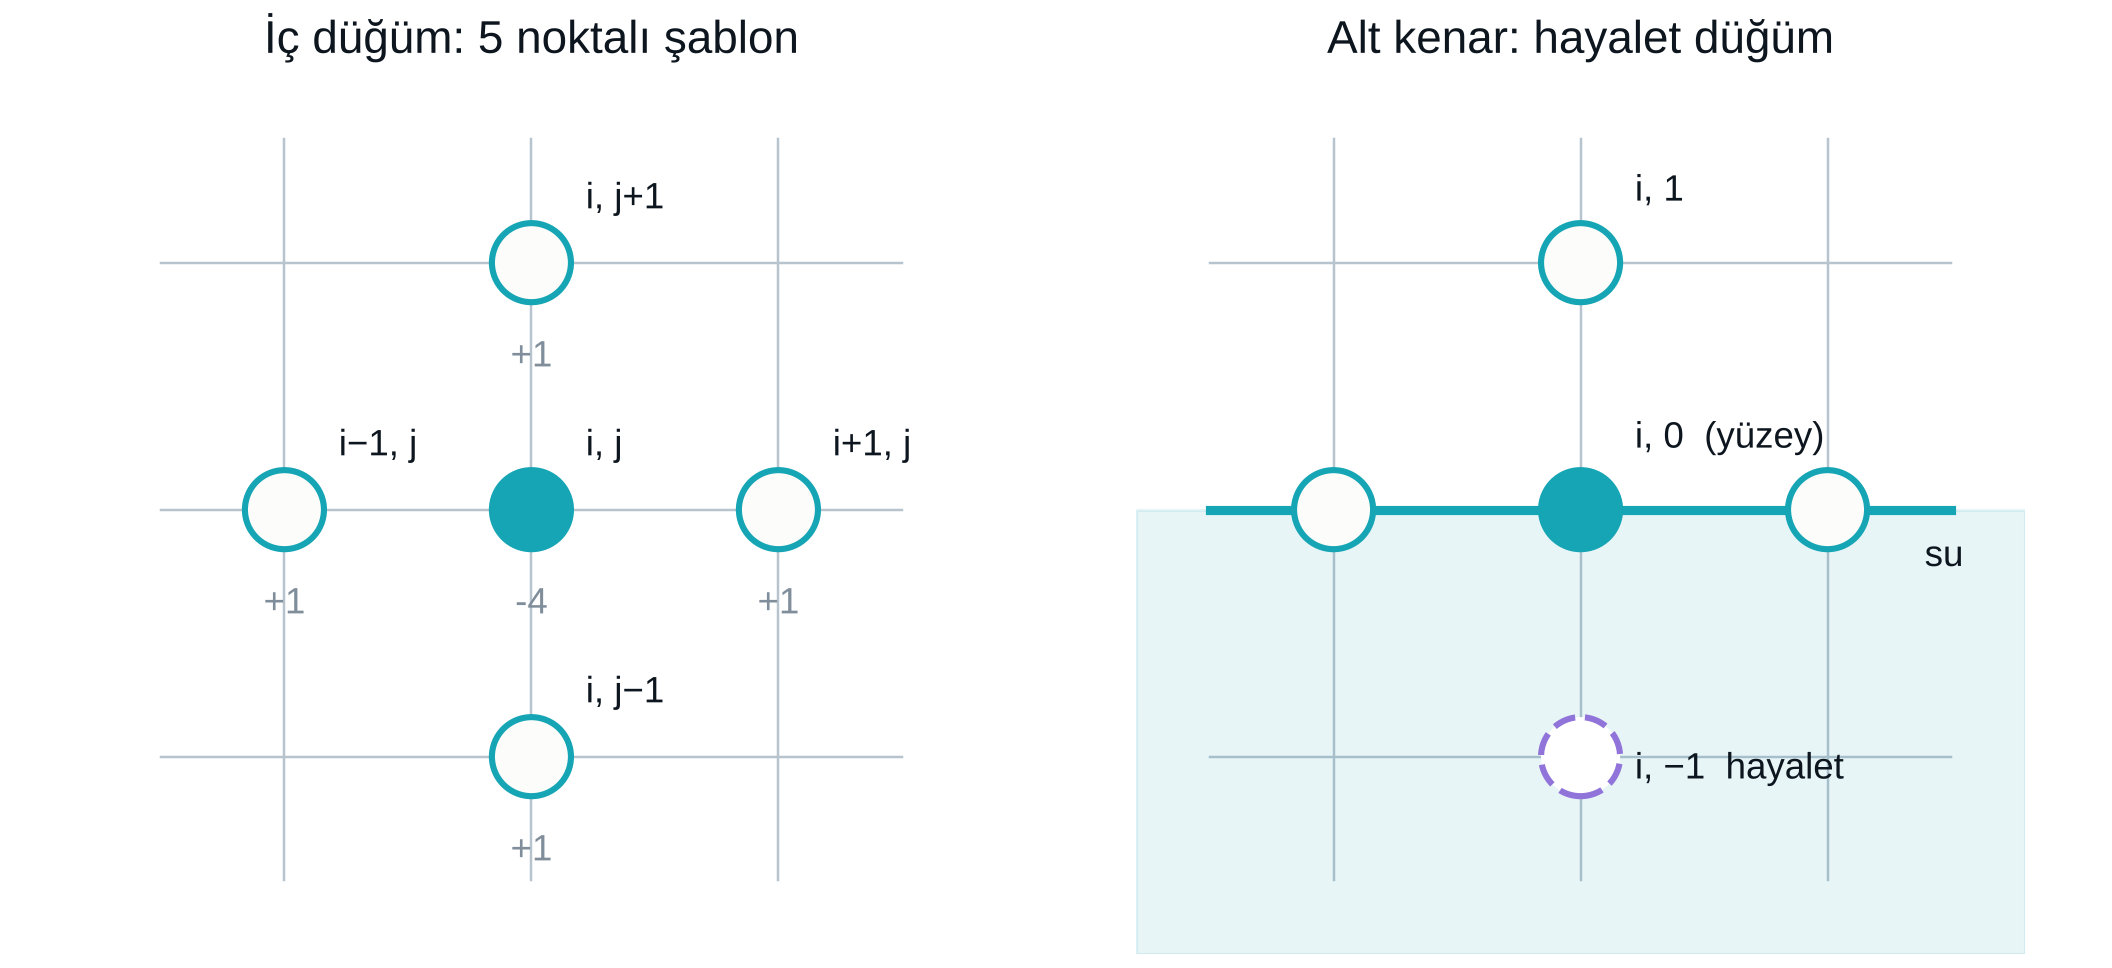

In [11]:
goster("03_stencil_ghost.png", 720)

### 3.4 Doğrusal sistemi kur: $\mathbf{A}\,\boldsymbol{\theta} = \mathbf{b}$

Her düğüme bir satır. Düğüm $(i, j)$ vektörde $p = jN + i$ konumunda. Dirichlet düğümlerine $\theta_p = 1$ satırı yazıyoruz
(sistemi kare ve basit tutar).

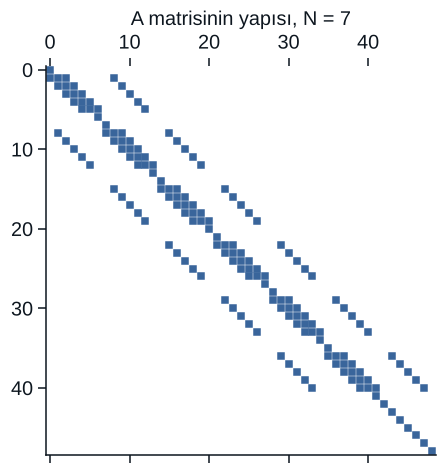

düğüm (3,0) satırı: {2: 1.0, 3: -5.632, 4: 1.0, 10: 2.0}


In [12]:
def kur(N, Bi):
    d = 1.0 / (N - 1)
    p = lambda i, j: j * N + i
    A = sp.lil_matrix((N * N, N * N))
    b = np.zeros(N * N)
    for j in range(N):
        for i in range(N):
            r = p(i, j)
            if i == 0 or i == N - 1 or j == N - 1:          # Dirichlet
                A[r, r] = 1.0; b[r] = 1.0
            elif j == 0:                                     # Robin + hayalet düğüm
                A[r, p(i - 1, j)] = A[r, p(i + 1, j)] = 1.0
                A[r, p(i, j + 1)] = 2.0
                A[r, r] = -(4.0 + 2.0 * d * Bi)
            else:                                            # iç düğüm
                A[r, p(i - 1, j)] = A[r, p(i + 1, j)] = 1.0
                A[r, p(i, j - 1)] = A[r, p(i, j + 1)] = 1.0
                A[r, r] = -4.0
    return A.tocsr(), b

A7, b7 = kur(7, Bi)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.spy(A7, markersize=4, color=C["celik_mavisi"])
ax.set_title("A matrisinin yapısı, N = 7", fontsize=13)
plt.show()

r = 0 * 7 + 3        # alt kenarın ortasındaki düğüm (i=3, j=0)
satir = A7.getrow(r)
print("düğüm (3,0) satırı:", {int(c): round(float(v), 3) for c, v in zip(satir.indices, satir.data)})

Satırda beklediğimiz dört katsayı var: iki yan komşu ($+1$), yukarıdaki düğüm ($+2$, hayalet düğümden gelen ikinci pay)
ve köşegen $-(4 + 2\Delta\,\mathrm{Bi})$.

### 3.5 Çöz

In [13]:
N = 101
t0 = time.perf_counter()
A, b = kur(N, Bi)
theta = spla.spsolve(A, b).reshape(N, N)      # theta[j, i]
print(f"N = {N}: {N*N:,} bilinmeyen, {A.nnz:,} sıfırdan farklı eleman, {time.perf_counter() - t0:.2f} s")

x = y = np.linspace(0, 1, N)
X, Y = np.meshgrid(x, y)
T = to_celsius(theta)
print(f"alt yüzey ortası: θ = {theta[0, N//2]:.4f}  ->  T = {T[0, N//2]:.2f} °C")

N = 101: 10,201 bilinmeyen, 49,702 sıfırdan farklı eleman, 0.10 s
alt yüzey ortası: θ = 0.3308  ->  T = 36.54 °C


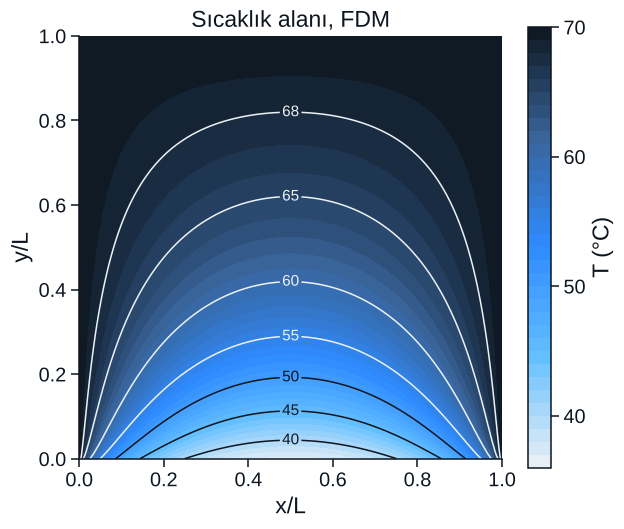

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
cf = ax.contourf(X, Y, T, levels=np.linspace(36, 70, 35), cmap=cmap_thermal)
for lv in [40, 45, 50, 55, 60, 65, 68]:
    cs = ax.contour(X, Y, T, levels=[lv], colors=[INK if lv < 52 else C["krom"]], linewidths=1.0)
    ax.clabel(cs, fmt="%d", fontsize=10, manual=[(0.5, float(np.interp(lv, T[:, N // 2], y)))])  # etiketler orta sütunda
ax.set(aspect="equal", xlabel="x/L", ylabel="y/L", title="Sıcaklık alanı, FDM")
fig.colorbar(cf, ax=ax, label="T (°C)", ticks=[40, 50, 60, 70])
plt.show()

Isı yan duvarlardan ve üstten gelip alt yüzeyden suya gidiyor; izotermler alta doğru kubbe şeklinde.
En soğuk nokta alt yüzeyin ortası.

---
## 4 · Analitik çözümle doğrula

### 4.1 Seri çözüm *(yüksek lisans)*

$\theta = 1 - \varphi$ yazınca $\varphi$ yan duvarlarda ve üstte sıfır olur. Sinüs serisi yan duvarları,
$\sinh$ terimi üst kenarı sağlar; Robin koşulu her modun katsayısını verir:

$$\theta(\xi,\eta) = 1 - \sum_{n\ \mathrm{tek}} A_n\,\sin(n\pi\xi)\,\sinh\!\big(n\pi(1-\eta)\big),
\qquad
A_n = \frac{4\,\mathrm{Bi}/(n\pi)}{n\pi\cosh(n\pi) + \mathrm{Bi}\,\sinh(n\pi)}$$

Büyük $n$'de $\cosh(n\pi)$ taşar. Oranı üstellerle yazarak taşmayı önlüyoruz:

$$\frac{\sinh\!\big(n\pi(1-\eta)\big)}{\cosh(n\pi)} = e^{-n\pi\eta}\,\frac{1 - e^{-2n\pi(1-\eta)}}{1 + e^{-2n\pi}}$$

In [15]:
def seri(x, y, Bi, terim=4000):
    X, Y = np.meshgrid(x, y)
    phi = np.zeros_like(X)
    for n in range(1, 2 * terim, 2):
        a = n * np.pi
        oran = np.exp(-a * Y) * (1 - np.exp(-2 * a * (1 - Y))) / (1 + np.exp(-2 * a))
        phi += (4 * Bi / a) / (a + Bi * np.tanh(a)) * np.sin(a * X) * oran
    return 1.0 - phi

theta_ex = seri(x, y, Bi)
print(f"seri çözüm, alt orta: θ = {theta_ex[0, N//2]:.4f}")

seri çözüm, alt orta: θ = 0.3308


### 4.2 Alt yüzeyde karşılaştır

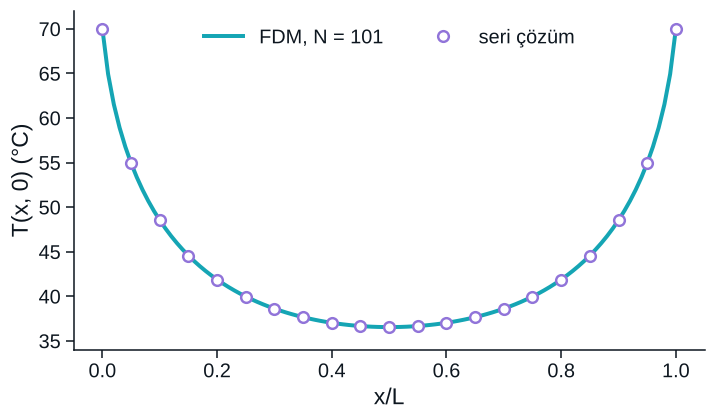

bağıl L2 hata = 1.08e-04
maksimum |hata| = 4.82e-03


In [16]:
fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(x, T[0], color=C["plan"], lw=2.6, label=f"FDM, N = {N}")
ax.plot(x[::5], to_celsius(theta_ex[0, ::5]), "o", ms=7, mfc="white", mec=C["lila"], mew=1.6, label="seri çözüm")
ax.set(xlabel="x/L", ylabel="T(x, 0) (°C)", ylim=(34, 72)); ax.legend(loc="upper center", ncol=2)
plt.show()

hata = theta - theta_ex
print(f"bağıl L2 hata = {np.linalg.norm(hata) / np.linalg.norm(theta_ex):.2e}")
print(f"maksimum |hata| = {np.abs(hata).max():.2e}")

### 4.3 Hata nerede?

Tek bir sayı yetmez. Hatanın logaritmasını haritalayalım:

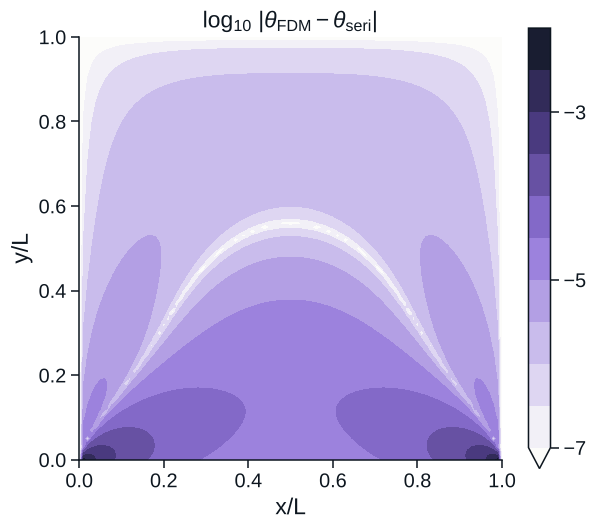

en büyük hata: (x/L, y/L) = (0.99, 0.00)


In [17]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
cc = ax.contourf(X, Y, np.log10(np.maximum(np.abs(hata), 1e-8)), levels=np.arange(-7, -1.99, 0.5),
                 cmap=cmap_error, extend="min")
ax.set(aspect="equal", xlabel="x/L", ylabel="y/L", title=r"$\log_{10}\,|\theta_{\mathrm{FDM}} - \theta_{\mathrm{seri}}|$")
fig.colorbar(cc, ax=ax, ticks=[-7, -5, -3])
plt.show()
j, i = np.unravel_index(np.abs(hata).argmax(), hata.shape)
print(f"en büyük hata: (x/L, y/L) = ({x[i]:.2f}, {y[j]:.2f})")

Hata **alt köşelerde** toplanıyor. Köşede yan duvar $\theta = 1$ istiyor, alt kenar soğumak istiyor; iki koşul uyumsuz ve
$\partial\theta/\partial\xi$ orada logaritmik olarak ıraksıyor. Ortadaki açık bant, hatanın işaret değiştirdiği gerçek bir sıfır.

**PINN için anlamı:** kolokasyon noktalarını köşelerde sıklaştırmak ve başarıyı toplam kayıpla değil, bu haritayla ölçmek.

### 4.4 Ağ yakınsaması *(yüksek lisans)*

Hata $\Delta^{p}$ ile azalıyorsa log-log grafikte eğim $p$'yi verir:

$$\|e\| \propto \Delta^{p} \quad\Longrightarrow\quad \log\|e\| = p\,\log\Delta + \text{sabit}$$

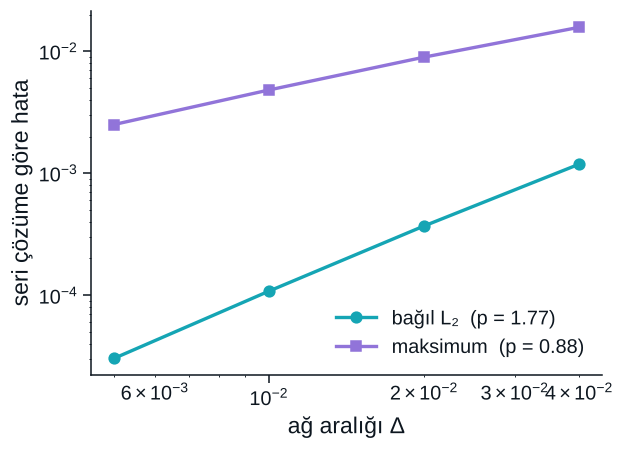

N =   26   L2 = 1.19e-03   max = 1.58e-02
N =   51   L2 = 3.69e-04   max = 8.97e-03
N =  101   L2 = 1.08e-04   max = 4.82e-03
N =  201   L2 = 3.03e-05   max = 2.51e-03


In [18]:
Ns = np.array([26, 51, 101, 201])
l2, linf = [], []
for n in Ns:
    An, bn = kur(n, Bi)
    tn = spla.spsolve(An, bn).reshape(n, n)
    xn = np.linspace(0, 1, n)
    en = seri(xn, xn, Bi)
    l2.append(np.linalg.norm(tn - en) / np.linalg.norm(en))
    linf.append(np.abs(tn - en).max())
d = 1 / (Ns - 1)
p2, pinf = (np.polyfit(np.log(d), np.log(v), 1)[0] for v in (l2, linf))

fig, ax = plt.subplots(figsize=(6.0, 4.3))
ax.loglog(d, l2, "o-", color=C["plan"], label=f"bağıl L₂  (p = {p2:.2f})")
ax.loglog(d, linf, "s-", color=C["lila"], label=f"maksimum  (p = {pinf:.2f})")
ax.set(xlabel="ağ aralığı Δ", ylabel="seri çözüme göre hata"); ax.legend()
plt.show()
for n, a, m in zip(Ns, l2, linf):
    print(f"N = {n:4d}   L2 = {a:.2e}   max = {m:.2e}")

L₂ hatası ikinci mertebeye yakın (şablonun teorik mertebesi), maksimum hata yalnızca birinci mertebe:
maksimum hata köşede ve orada çözüm düzgün olmadığı için Taylor kesme hatası varsayımı bozuluyor.

<details><summary>🔎 <b>Kontrol sorusu:</b> N'yi 101'den 201'e çıkarırsak maksimum hata kaç kat azalır?</summary>

Yaklaşık 2 kat (birinci mertebe). L₂ hatası ise yaklaşık 3.5 kat azalır. Fark köşe tekilliğinden geliyor.
</details>

---
## 5 · Mühendislik sonucu: alttan çekilen ısı

$$Q' = \bar h\,L\,(T_w - T_\infty)\int_0^1 \theta(\xi, 0)\,d\xi \qquad [\mathrm{W/m}]$$

In [19]:
I_fdm = np.trapezoid(theta[0], x)
xf = np.linspace(0, 1, 4001)
I_ser = np.trapezoid(seri(xf, np.array([0.0]), Bi)[0], xf)
Q = h * L * dT * I_fdm
print(f"∫θ(ξ,0)dξ:  FDM = {I_fdm:.4f}   seri = {I_ser:.4f}")
print(f"Q' ≈ {Q:,.0f} W/m  (birim derinlik başına)")

∫θ(ξ,0)dξ:  FDM = 0.4618   seri = 0.4612
Q' ≈ 5,537 W/m  (birim derinlik başına)


### Repodaki çözücüyle çapraz kontrol

Bu defterde adım adım yazdığımız çözücü, repodaki `fdm_solver.py` ile aynı sonucu vermeli:

In [20]:
sys.path.insert(0, str(CASE))
from fdm_solver import solve_fdm
_, _, theta_repo = solve_fdm(N, Bi)
print(f"max |defter − repo| = {np.abs(theta - theta_repo).max():.1e}")

max |defter − repo| = 0.0e+00


---
## Özet

| | Sonuç |
|---|---|
| Biot sayısı | $\mathrm{Bi} \approx 4.9$: güçlü gradyan |
| En düşük sıcaklık | alt yüzey ortası, $\approx 36.5\,^\circ\mathrm{C}$ |
| Alttan çekilen ısı | $Q' \approx 5.5$ kW/m |
| Doğrulama | bağıl $L_2 \approx 1.1\times10^{-4}$ ($N = 101$) |
| Zorluk | alt köşeler: maksimum hata birinci mertebe |

**Sıradaki ders:** aynı problemi veri kullanmadan bir sinir ağıyla çözeceğiz. Dirichlet kenarlarını ağın yapısına gömeceğiz:

$$\hat\theta = 1 + \xi(1-\xi)(1-\eta)\,\mathcal{N}(\xi,\eta),
\qquad
\mathcal{L} = \big\|\nabla^2\hat\theta\big\|^2 + \Big\|\frac{\partial\hat\theta}{\partial\eta} - \mathrm{Bi}\,\hat\theta\Big\|^2_{\eta=0}$$

## Alıştırmalar

**Lisans**
1. `Bi = 2000 * L / k` ile çözün; alt orta sıcaklığı karşılaştırın.
2. Alüminyum–hava için Bi'yi hesaplayın ve alt yüzey profilini çizin.
3. $Q'$'yü yamuk kuralıyla elle doğrulayın.

**Yüksek lisans**
1. Richardson ekstrapolasyonu ile ağdan bağımsız $Q'$ tahmini yapın.
2. Köşe tekilliğinin yerel mertebesini log-log ile ölçün.
3. Film sıcaklığı (35 °C) özellikleriyle Bi duyarlılığını tartışın.

In [21]:
# Alıştırma alanı — Lisans 1 ile başlayın:
Bi_1 = 2000 * L / k
A1, b1 = kur(101, Bi_1)
theta_1 = spla.spsolve(A1, b1).reshape(101, 101)
print(f"Bi = {Bi_1:.2f}: alt orta T = {to_celsius(theta_1[0, 50]):.2f} °C   (Bi = {Bi:.2f} ile {T[0, 50]:.2f} °C)")

Bi = 4.08: alt orta T = 38.76 °C   (Bi = 4.89 ile 36.54 °C)
